<a href="https://colab.research.google.com/github/AmirthaaR/Model-MRI/blob/main/Model_MRI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("NumPy version:", np.__version__)

TensorFlow version: 2.20.0
NumPy version: 2.1.3


In [ ]:
!pip install -q kaggle

In [ ]:
!kaggle datasets download -d masoudnickparvar/brain-tumor-mri-dataset

Dataset URL: https://www.kaggle.com/datasets/masoudnickparvar/brain-tumor-mri-dataset
License(s): Attribution 4.0 International (CC BY 4.0)
100% 157M/157M [00:05<00:00, 31.9MB/s]



In [ ]:
!unzip -q brain-tumor-mri-dataset.zip -d /content/brain_tumor_dataset

In [ ]:
import os

dataset_path = "/content/brain_tumor_dataset"

print("Dataset contents:", os.listdir(dataset_path))

Dataset contents: ['Testing', 'Training']


In [ ]:
training_path = os.path.join(dataset_path, "Training")
testing_path = os.path.join(dataset_path, "Testing")

print("Training path:", training_path)
print("Testing path:", testing_path)

print("Classes:", os.listdir(training_path))

Training path: /content/brain_tumor_dataset/Training
Testing path: /content/brain_tumor_dataset/Testing
Classes: ['pituitary', 'glioma', 'notumor', 'meningioma']


In [ ]:
import tensorflow as tf

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

# Training set: 80%
train_ds = tf.keras.utils.image_dataset_from_directory(
    training_path,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

# Validation set: 20%
val_ds = tf.keras.utils.image_dataset_from_directory(
    training_path,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

# Test set: completely separate
test_ds = tf.keras.utils.image_dataset_from_directory(
    testing_path,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

class_names = train_ds.class_names
num_classes = len(class_names)

print("Class names:", class_names)
print("Number of classes:", num_classes)

Found 5600 files belonging to 4 classes.
Using 4480 files for training.
Found 5600 files belonging to 4 classes.
Using 1120 files for validation.
Found 1600 files belonging to 4 classes.
Class names: ['glioma', 'meningioma', 'notumor', 'pituitary']
Number of classes: 4


In [ ]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

print("Dataset pipeline ready!")

Dataset pipeline ready!


In [ ]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1),
], name="data_augmentation")

# **MobileNetV2**

In [ ]:
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

print("MobileNetV2 loaded.")
print("Total layers:", len(base_model.layers))

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
MobileNetV2 loaded.
Total layers: 154


In [ ]:
model = tf.keras.Sequential([
    data_augmentation,

    base_model,

    tf.keras.layers.GlobalAveragePooling2D(),

    tf.keras.layers.Dropout(0.3),

    tf.keras.layers.Dense(
        num_classes,
        activation="softmax"
    )
])

model.build((None, 224, 224, 3))

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,263,108 (8.63 MB)

 Trainable params: 5,124 (20.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully.")

Model compiled successfully.


In [ ]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30,
    callbacks=[early_stopping]
)

Epoch 1/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 22s 88ms/step - accuracy: 0.5991 - loss: 0.9849 - val_accuracy: 0.7482 - val_loss: 0.6514
Epoch 2/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 10s 73ms/step - accuracy: 0.7496 - loss: 0.6496 - val_accuracy: 0.7705 - val_loss: 0.5799
Epoch 3/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 10s 69ms/step - accuracy: 0.7779 - loss: 0.5859 - val_accuracy: 0.7750 - val_loss: 0.5668
Epoch 4/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 10s 74ms/step - accuracy: 0.7873 - loss: 0.5490 - val_accuracy: 0.7750 - val_loss: 0.5640
Epoch 5/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 10s 75ms/step - accuracy: 0.7989 - loss: 0.5378 - val_accuracy: 0.7688 - val_loss: 0.5540
Epoch 6/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 10s 75ms/step - accuracy: 0.8025 - loss: 0.5176 - val_accuracy: 0.7875 - val_loss: 0.5416
Epoch 7/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 11s 76ms/step - accuracy: 0.8203 - loss: 0.4930 - val_accuracy: 0.7777 - val_loss: 0.5470
Epoch 8/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 20s 76ms/step - accuracy: 0.8100 - loss: 0.4884 - 

In [ ]:
test_loss, test_accuracy = model.evaluate(test_ds)

print("MobileNetV2 Baseline Test Loss:", test_loss)
print("MobileNetV2 Baseline Test Accuracy:", test_accuracy)

50/50 ━━━━━━━━━━━━━━━━━━━━ 3s 55ms/step - accuracy: 0.7163 - loss: 0.8188
MobileNetV2 Baseline Test Loss: 0.8187858462333679
MobileNetV2 Baseline Test Accuracy: 0.7162500023841858


In [ ]:
from sklearn.metrics import confusion_matrix, classification_report
import numpy as np
import matplotlib.pyplot as plt

y_true = []
y_pred = []

for images, labels in test_ds:
    predictions = model.predict(images, verbose=0)

    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(predictions, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

print("MobileNetV2 Baseline Classification Report\n")
print(
    classification_report(
        y_true,
        y_pred,
        target_names=class_names
    )
)

MobileNetV2 Baseline Classification Report

              precision    recall  f1-score   support

      glioma       0.63      0.71      0.67       400
  meningioma       0.78      0.23      0.35       400
     notumor       0.68      1.00      0.81       400
   pituitary       0.84      0.93      0.88       400

    accuracy                           0.72      1600
   macro avg       0.73      0.72      0.68      1600
weighted avg       0.73      0.72      0.68      1600



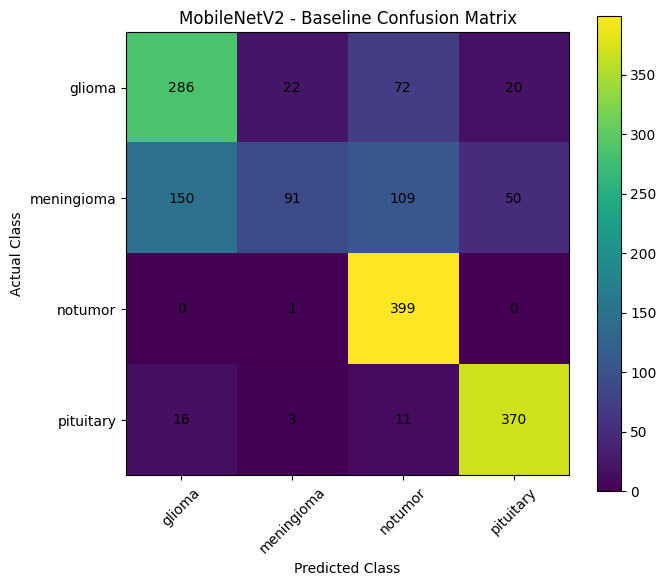

In [ ]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(7, 6))
plt.imshow(cm)

plt.title("MobileNetV2 - Baseline Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.xticks(
    range(len(class_names)),
    class_names,
    rotation=45
)

plt.yticks(
    range(len(class_names)),
    class_names
)

for i in range(len(class_names)):
    for j in range(len(class_names)):
        plt.text(
            j, i, cm[i, j],
            ha="center",
            va="center"
        )

plt.colorbar()
plt.tight_layout()
plt.show()

In [ ]:
base_model.trainable = True

# Freeze the earlier layers
for layer in base_model.layers[:-30]:
    layer.trainable = False

print("Total layers:", len(base_model.layers))
print(
    "Trainable layers:",
    sum(layer.trainable for layer in base_model.layers)
)

Total layers: 154
Trainable layers: 30


In [ ]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("MobileNetV2 recompiled for fine-tuning.")

MobileNetV2 recompiled for fine-tuning.


In [ ]:
fine_tune_early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history_fine = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30,
    callbacks=[fine_tune_early_stopping]
)

Epoch 1/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 27s 128ms/step - accuracy: 0.5071 - loss: 2.6153 - val_accuracy: 0.5670 - val_loss: 1.2412
Epoch 2/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 14s 99ms/step - accuracy: 0.7580 - loss: 0.6773 - val_accuracy: 0.6366 - val_loss: 0.9622
Epoch 3/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 13s 94ms/step - accuracy: 0.7931 - loss: 0.5719 - val_accuracy: 0.7018 - val_loss: 0.7296
Epoch 4/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 13s 93ms/step - accuracy: 0.8033 - loss: 0.5355 - val_accuracy: 0.7670 - val_loss: 0.5814
Epoch 5/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 14s 98ms/step - accuracy: 0.8083 - loss: 0.5010 - val_accuracy: 0.7920 - val_loss: 0.5443
Epoch 6/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 14s 100ms/step - accuracy: 0.8183 - loss: 0.4684 - val_accuracy: 0.8009 - val_loss: 0.5181
Epoch 7/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 13s 96ms/step - accuracy: 0.8281 - loss: 0.4485 - val_accuracy: 0.8161 - val_loss: 0.4881
Epoch 8/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 14s 100ms/step - accuracy: 0.8384 - loss: 0.4196

In [ ]:
test_loss_fine, test_accuracy_fine = model.evaluate(test_ds)

print("Fine-tuned MobileNetV2 Test Loss:", test_loss_fine)
print("Fine-tuned MobileNetV2 Test Accuracy:", test_accuracy_fine)

50/50 ━━━━━━━━━━━━━━━━━━━━ 3s 58ms/step - accuracy: 0.7356 - loss: 0.9792
Fine-tuned MobileNetV2 Test Loss: 0.979180097579956
Fine-tuned MobileNetV2 Test Accuracy: 0.7356250286102295


In [ ]:
from sklearn.metrics import confusion_matrix, classification_report
import numpy as np
import matplotlib.pyplot as plt

y_true_ft = []
y_pred_ft = []

for images, labels in test_ds:
    predictions = model.predict(images, verbose=0)

    y_true_ft.extend(labels.numpy())
    y_pred_ft.extend(np.argmax(predictions, axis=1))

y_true_ft = np.array(y_true_ft)
y_pred_ft = np.array(y_pred_ft)

print("MobileNetV2 Fine-tuned Classification Report\n")

print(
    classification_report(
        y_true_ft,
        y_pred_ft,
        target_names=class_names
    )
)

MobileNetV2 Fine-tuned Classification Report

              precision    recall  f1-score   support

      glioma       0.64      0.73      0.68       400
  meningioma       0.79      0.32      0.46       400
     notumor       0.68      1.00      0.81       400
   pituitary       0.91      0.90      0.90       400

    accuracy                           0.74      1600
   macro avg       0.75      0.74      0.71      1600
weighted avg       0.75      0.74      0.71      1600



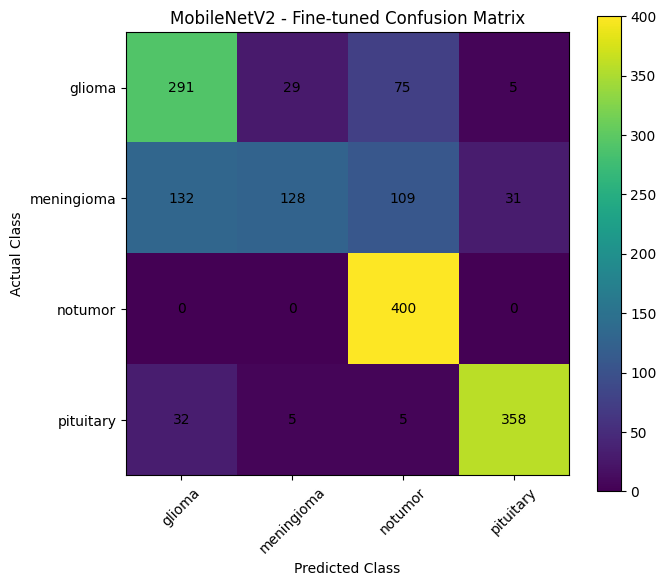

In [ ]:
cm_ft = confusion_matrix(y_true_ft, y_pred_ft)

plt.figure(figsize=(7, 6))
plt.imshow(cm_ft)

plt.title("MobileNetV2 - Fine-tuned Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.xticks(
    range(len(class_names)),
    class_names,
    rotation=45
)

plt.yticks(
    range(len(class_names)),
    class_names
)

for i in range(len(class_names)):
    for j in range(len(class_names)):
        plt.text(
            j, i, cm_ft[i, j],
            ha="center",
            va="center"
        )

plt.colorbar()
plt.tight_layout()
plt.show()

# **MobileNetV3Small**

In [ ]:
base_model_v3 = tf.keras.applications.MobileNetV3Small(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

base_model_v3.trainable = False

print("MobileNetV3Small loaded.")
print("Total layers:", len(base_model_v3.layers))

4334752/4334752 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
MobileNetV3Small loaded.
Total layers: 157


In [ ]:
model_v3 = tf.keras.Sequential([
    data_augmentation,

    base_model_v3,

    tf.keras.layers.GlobalAveragePooling2D(),

    tf.keras.layers.Dropout(0.3),

    tf.keras.layers.Dense(
        num_classes,
        activation="softmax"
    )
])

model_v3.build((None, 224, 224, 3))

model_v3.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MobileNetV3Small (Functional)   │ (None, 7, 7, 576)      │       939,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 576)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 576)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         2,308 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 941,428 (3.59 MB)

 Trainable params: 2,308 (9.02 KB)

 Non-trainable params: 939,120 (3.58 MB)

In [ ]:
model_v3.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("MobileNetV3Small compiled successfully.")

MobileNetV3Small compiled successfully.


In [ ]:
early_stopping_v3 = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history_v3 = model_v3.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30,
    callbacks=[early_stopping_v3]
)

Epoch 1/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 15s 72ms/step - accuracy: 0.6121 - loss: 0.9347 - val_accuracy: 0.8330 - val_loss: 0.5356
Epoch 2/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 9s 62ms/step - accuracy: 0.7824 - loss: 0.5721 - val_accuracy: 0.8420 - val_loss: 0.4425
Epoch 3/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 9s 54ms/step - accuracy: 0.8156 - loss: 0.4901 - val_accuracy: 0.8438 - val_loss: 0.4196
Epoch 4/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 9s 63ms/step - accuracy: 0.8328 - loss: 0.4487 - val_accuracy: 0.8580 - val_loss: 0.3959
Epoch 5/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 11s 71ms/step - accuracy: 0.8455 - loss: 0.4125 - val_accuracy: 0.8750 - val_loss: 0.3661
Epoch 6/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 9s 61ms/step - accuracy: 0.8480 - loss: 0.3968 - val_accuracy: 0.8830 - val_loss: 0.3525
Epoch 7/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 10s 61ms/step - accuracy: 0.8538 - loss: 0.3871 - val_accuracy: 0.8777 - val_loss: 0.3548
Epoch 8/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 10s 72ms/step - accuracy: 0.8560 - loss: 0.3862 - val_

In [ ]:
test_loss_v3, test_accuracy_v3 = model_v3.evaluate(test_ds)

print("MobileNetV3Small Baseline Test Loss:", test_loss_v3)
print("MobileNetV3Small Baseline Test Accuracy:", test_accuracy_v3)

50/50 ━━━━━━━━━━━━━━━━━━━━ 4s 83ms/step - accuracy: 0.8363 - loss: 0.5125
MobileNetV3Small Baseline Test Loss: 0.5124906301498413
MobileNetV3Small Baseline Test Accuracy: 0.8362500071525574


In [ ]:
from sklearn.metrics import confusion_matrix, classification_report
import numpy as np
import matplotlib.pyplot as plt

y_true_v3 = []
y_pred_v3 = []

for images, labels in test_ds:
    predictions = model_v3.predict(images, verbose=0)

    y_true_v3.extend(labels.numpy())
    y_pred_v3.extend(np.argmax(predictions, axis=1))

y_true_v3 = np.array(y_true_v3)
y_pred_v3 = np.array(y_pred_v3)

print("MobileNetV3Small Baseline Classification Report\n")

print(
    classification_report(
        y_true_v3,
        y_pred_v3,
        target_names=class_names
    )
)

MobileNetV3Small Baseline Classification Report

              precision    recall  f1-score   support

      glioma       0.92      0.66      0.77       400
  meningioma       0.74      0.74      0.74       400
     notumor       0.85      0.98      0.91       400
   pituitary       0.86      0.96      0.91       400

    accuracy                           0.84      1600
   macro avg       0.84      0.84      0.83      1600
weighted avg       0.84      0.84      0.83      1600



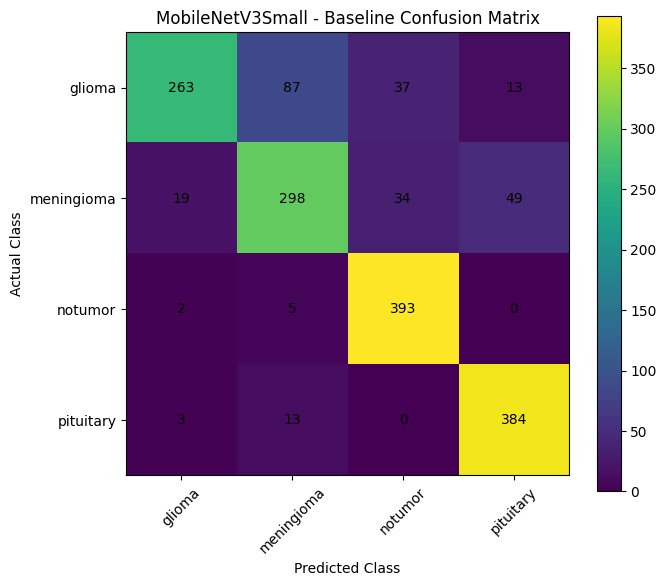

In [ ]:
cm_v3 = confusion_matrix(y_true_v3, y_pred_v3)

plt.figure(figsize=(7, 6))
plt.imshow(cm_v3)

plt.title("MobileNetV3Small - Baseline Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.xticks(
    range(len(class_names)),
    class_names,
    rotation=45
)

plt.yticks(
    range(len(class_names)),
    class_names
)

for i in range(len(class_names)):
    for j in range(len(class_names)):
        plt.text(
            j, i, cm_v3[i, j],
            ha="center",
            va="center"
        )

plt.colorbar()
plt.tight_layout()
plt.show()

In [ ]:
base_model_v3.trainable = True

# Freeze earlier layers
for layer in base_model_v3.layers[:-30]:
    layer.trainable = False

print("Total layers:", len(base_model_v3.layers))
print(
    "Trainable layers:",
    sum(layer.trainable for layer in base_model_v3.layers)
)

Total layers: 157
Trainable layers: 30


In [ ]:
model_v3.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [ ]:
fine_tune_early_stopping_v3 = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history_ft_v3 = model_v3.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30,
    callbacks=[fine_tune_early_stopping_v3]
)

Epoch 1/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 10s 74ms/step - accuracy: 0.7984 - loss: 0.5722 - val_accuracy: 0.7884 - val_loss: 0.5162
Epoch 2/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 8s 60ms/step - accuracy: 0.8254 - loss: 0.4793 - val_accuracy: 0.7795 - val_loss: 0.5418
Epoch 3/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 11s 68ms/step - accuracy: 0.8313 - loss: 0.4403 - val_accuracy: 0.7902 - val_loss: 0.5093
Epoch 4/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 11s 77ms/step - accuracy: 0.8422 - loss: 0.4108 - val_accuracy: 0.7973 - val_loss: 0.4769
Epoch 5/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 10s 69ms/step - accuracy: 0.8583 - loss: 0.3886 - val_accuracy: 0.8098 - val_loss: 0.4512
Epoch 6/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 10s 68ms/step - accuracy: 0.8540 - loss: 0.3681 - val_accuracy: 0.8259 - val_loss: 0.4184
Epoch 7/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 8s 60ms/step - accuracy: 0.8665 - loss: 0.3582 - val_accuracy: 0.8366 - val_loss: 0.3963
Epoch 8/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 11s 63ms/step - accuracy: 0.8645 - loss: 0.3516 - va

In [ ]:
test_loss_ft_v3, test_accuracy_ft_v3 = model_v3.evaluate(test_ds)

print("Fine-tuned MobileNetV3Small Test Loss:", test_loss_ft_v3)
print("Fine-tuned MobileNetV3Small Test Accuracy:", test_accuracy_ft_v3)

50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 46ms/step - accuracy: 0.8662 - loss: 0.5166
Fine-tuned MobileNetV3Small Test Loss: 0.5166486501693726
Fine-tuned MobileNetV3Small Test Accuracy: 0.8662499785423279


In [ ]:
from sklearn.metrics import confusion_matrix, classification_report
import numpy as np
import matplotlib.pyplot as plt

y_true_ft_v3 = []
y_pred_ft_v3 = []

for images, labels in test_ds:
    predictions = model_v3.predict(images, verbose=0)

    y_true_ft_v3.extend(labels.numpy())
    y_pred_ft_v3.extend(np.argmax(predictions, axis=1))

y_true_ft_v3 = np.array(y_true_ft_v3)
y_pred_ft_v3 = np.array(y_pred_ft_v3)

print("MobileNetV3Small Fine-tuned Classification Report\n")

print(
    classification_report(
        y_true_ft_v3,
        y_pred_ft_v3,
        target_names=class_names
    )
)

MobileNetV3Small Fine-tuned Classification Report

              precision    recall  f1-score   support

      glioma       0.98      0.68      0.80       400
  meningioma       0.79      0.81      0.80       400
     notumor       0.90      0.98      0.94       400
   pituitary       0.83      0.99      0.90       400

    accuracy                           0.87      1600
   macro avg       0.88      0.87      0.86      1600
weighted avg       0.88      0.87      0.86      1600



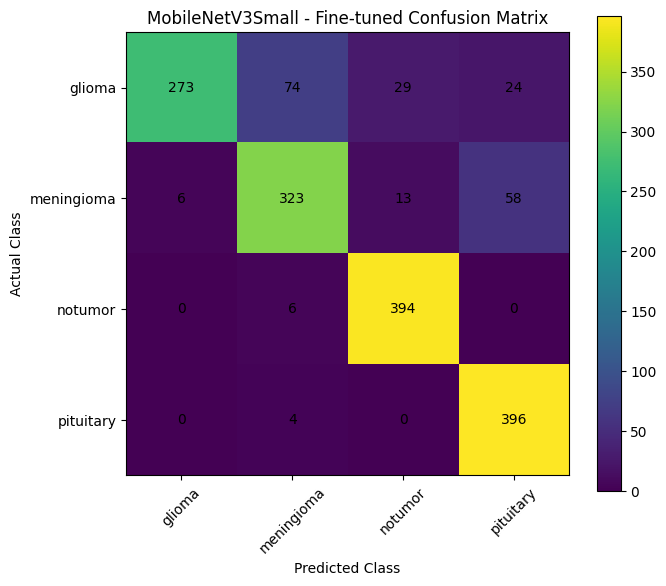

In [ ]:
cm_ft_v3 = confusion_matrix(y_true_ft_v3, y_pred_ft_v3)

plt.figure(figsize=(7, 6))
plt.imshow(cm_ft_v3)

plt.title("MobileNetV3Small - Fine-tuned Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.xticks(
    range(len(class_names)),
    class_names,
    rotation=45
)

plt.yticks(
    range(len(class_names)),
    class_names
)

for i in range(len(class_names)):
    for j in range(len(class_names)):
        plt.text(
            j, i, cm_ft_v3[i, j],
            ha="center",
            va="center"
        )

plt.colorbar()
plt.tight_layout()
plt.show()

# **EfficientNetB0**

In [ ]:
base_model_eff = tf.keras.applications.EfficientNetB0(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

base_model_eff.trainable = False

print("EfficientNetB0 loaded.")
print("Total layers:", len(base_model_eff.layers))

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
EfficientNetB0 loaded.
Total layers: 238


In [ ]:
model_eff = tf.keras.Sequential([
    data_augmentation,

    base_model_eff,

    tf.keras.layers.GlobalAveragePooling2D(),

    tf.keras.layers.Dropout(0.3),

    tf.keras.layers.Dense(
        num_classes,
        activation="softmax"
    )
])

model_eff.build((None, 224, 224, 3))

model_eff.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,054,695 (15.47 MB)

 Trainable params: 5,124 (20.02 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [ ]:
model_eff.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("EfficientNetB0 compiled successfully.")

EfficientNetB0 compiled successfully.


In [ ]:
early_stopping_eff = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history_eff = model_eff.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30,
    callbacks=[early_stopping_eff]
)

Epoch 1/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 27s 120ms/step - accuracy: 0.6897 - loss: 0.7825 - val_accuracy: 0.8250 - val_loss: 0.5171
Epoch 2/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 14s 100ms/step - accuracy: 0.8181 - loss: 0.5060 - val_accuracy: 0.8232 - val_loss: 0.4484
Epoch 3/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 20s 98ms/step - accuracy: 0.8379 - loss: 0.4544 - val_accuracy: 0.8562 - val_loss: 0.3993
Epoch 4/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 20s 98ms/step - accuracy: 0.8446 - loss: 0.4167 - val_accuracy: 0.8804 - val_loss: 0.3690
Epoch 5/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 21s 98ms/step - accuracy: 0.8542 - loss: 0.3940 - val_accuracy: 0.8634 - val_loss: 0.3727
Epoch 6/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 21s 99ms/step - accuracy: 0.8589 - loss: 0.3861 - val_accuracy: 0.8616 - val_loss: 0.3662
Epoch 7/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 14s 99ms/step - accuracy: 0.8592 - loss: 0.3766 - val_accuracy: 0.8857 - val_loss: 0.3299
Epoch 8/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 14s 98ms/step - accuracy: 0.8643 - loss: 0.3686 

In [ ]:
test_loss_eff, test_accuracy_eff = model_eff.evaluate(test_ds)

print("EfficientNetB0 Baseline Test Loss:", test_loss_eff)
print("EfficientNetB0 Baseline Test Accuracy:", test_accuracy_eff)

50/50 ━━━━━━━━━━━━━━━━━━━━ 4s 79ms/step - accuracy: 0.8469 - loss: 0.4825
EfficientNetB0 Baseline Test Loss: 0.48248812556266785
EfficientNetB0 Baseline Test Accuracy: 0.846875011920929


In [ ]:
from sklearn.metrics import confusion_matrix, classification_report
import numpy as np
import matplotlib.pyplot as plt

y_true_eff = []
y_pred_eff = []

for images, labels in test_ds:
    predictions = model_eff.predict(images, verbose=0)

    y_true_eff.extend(labels.numpy())
    y_pred_eff.extend(np.argmax(predictions, axis=1))

y_true_eff = np.array(y_true_eff)
y_pred_eff = np.array(y_pred_eff)

print("EfficientNetB0 Baseline Classification Report\n")

print(
    classification_report(
        y_true_eff,
        y_pred_eff,
        target_names=class_names
    )
)

EfficientNetB0 Baseline Classification Report

              precision    recall  f1-score   support

      glioma       0.90      0.64      0.74       400
  meningioma       0.75      0.79      0.77       400
     notumor       0.89      0.98      0.93       400
   pituitary       0.85      0.99      0.92       400

    accuracy                           0.85      1600
   macro avg       0.85      0.85      0.84      1600
weighted avg       0.85      0.85      0.84      1600



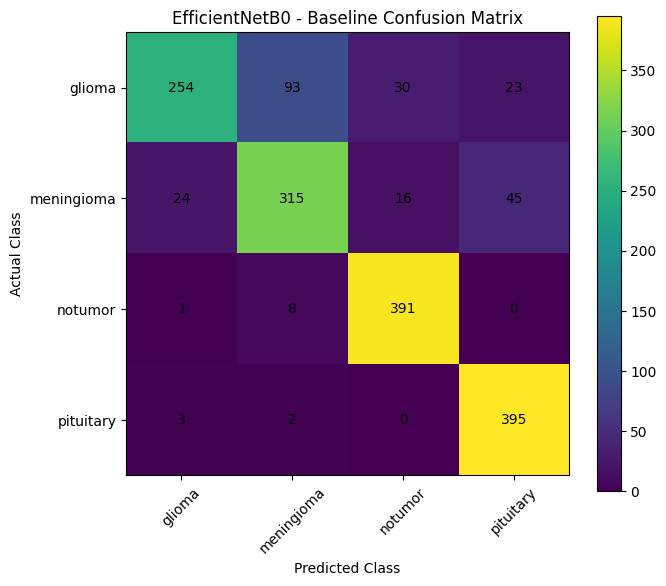

In [ ]:
cm_eff = confusion_matrix(y_true_eff, y_pred_eff)

plt.figure(figsize=(7, 6))
plt.imshow(cm_eff)

plt.title("EfficientNetB0 - Baseline Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.xticks(
    range(len(class_names)),
    class_names,
    rotation=45
)

plt.yticks(
    range(len(class_names)),
    class_names
)

for i in range(len(class_names)):
    for j in range(len(class_names)):
        plt.text(
            j, i, cm_eff[i, j],
            ha="center",
            va="center"
        )

plt.colorbar()
plt.tight_layout()
plt.show()

In [ ]:
# Enable the EfficientNetB0 backbone
base_model_eff.trainable = True

# Freeze all layers except the last 30
for layer in base_model_eff.layers[:-30]:
    layer.trainable = False

# Keep the last 30 layers trainable
for layer in base_model_eff.layers[-30:]:
    layer.trainable = True

print("Total layers:", len(base_model_eff.layers))
print("Trainable layers:", sum(layer.trainable for layer in base_model_eff.layers))

Total layers: 238
Trainable layers: 30


In [ ]:
model_eff.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [ ]:
history_eff_ft = model_eff.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30,
    callbacks=[early_stopping_eff]
)

Epoch 1/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 16s 116ms/step - accuracy: 0.8165 - loss: 0.4781 - val_accuracy: 0.8580 - val_loss: 0.3569
Epoch 2/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 17s 120ms/step - accuracy: 0.8415 - loss: 0.4268 - val_accuracy: 0.8723 - val_loss: 0.3276
Epoch 3/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 20s 114ms/step - accuracy: 0.8453 - loss: 0.4023 - val_accuracy: 0.8741 - val_loss: 0.3131
Epoch 4/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 16s 114ms/step - accuracy: 0.8594 - loss: 0.3714 - val_accuracy: 0.8768 - val_loss: 0.3003
Epoch 5/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 16s 117ms/step - accuracy: 0.8710 - loss: 0.3438 - val_accuracy: 0.8813 - val_loss: 0.2985


In [ ]:
test_loss_eff_ft, test_accuracy_eff_ft = model_eff.evaluate(test_ds)

print("Fine-tuned EfficientNetB0 Test Loss:", test_loss_eff_ft)
print("Fine-tuned EfficientNetB0 Test Accuracy:", test_accuracy_eff_ft)

50/50 ━━━━━━━━━━━━━━━━━━━━ 4s 79ms/step - accuracy: 0.7975 - loss: 0.6069
Fine-tuned EfficientNetB0 Test Loss: 0.6069164872169495
Fine-tuned EfficientNetB0 Test Accuracy: 0.7975000143051147


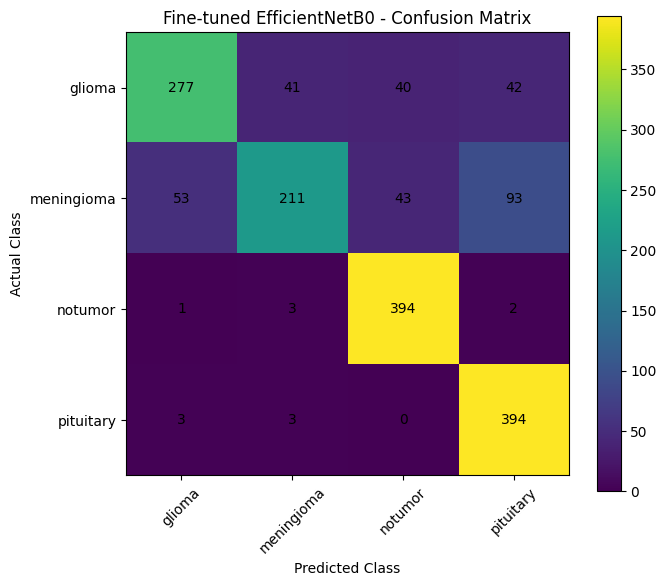

In [ ]:
from sklearn.metrics import confusion_matrix
import numpy as np
import matplotlib.pyplot as plt

y_true_eff_ft = []
y_pred_eff_ft = []

for images, labels in test_ds:
    predictions = model_eff.predict(images, verbose=0)

    y_true_eff_ft.extend(labels.numpy())
    y_pred_eff_ft.extend(np.argmax(predictions, axis=1))

y_true_eff_ft = np.array(y_true_eff_ft)
y_pred_eff_ft = np.array(y_pred_eff_ft)

cm_eff_ft = confusion_matrix(y_true_eff_ft, y_pred_eff_ft)

plt.figure(figsize=(7, 6))
plt.imshow(cm_eff_ft)

plt.title("Fine-tuned EfficientNetB0 - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.xticks(range(len(class_names)), class_names, rotation=45)
plt.yticks(range(len(class_names)), class_names)

for i in range(len(class_names)):
    for j in range(len(class_names)):
        plt.text(j, i, cm_eff_ft[i, j],
                 ha="center", va="center")

plt.colorbar()
plt.tight_layout()
plt.show()

# **EfficientNetV2B0**

In [ ]:
import tensorflow as tf

base_model_v2b0 = tf.keras.applications.EfficientNetV2B0(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

base_model_v2b0.trainable = False

print("EfficientNetV2B0 loaded.")
print("Total layers:", len(base_model_v2b0.layers))

24274472/24274472 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
EfficientNetV2B0 loaded.
Total layers: 270


In [ ]:
model_v2b0 = tf.keras.Sequential([
    data_augmentation,

    base_model_v2b0,

    tf.keras.layers.GlobalAveragePooling2D(),

    tf.keras.layers.Dropout(0.3),

    tf.keras.layers.Dense(
        num_classes,
        activation="softmax"
    )
])

model_v2b0.build((None, 224, 224, 3))

model_v2b0.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetv2-b0 (Functional)  │ (None, 7, 7, 1280)     │     5,919,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,924,436 (22.60 MB)

 Trainable params: 5,124 (20.02 KB)

 Non-trainable params: 5,919,312 (22.58 MB)

In [ ]:
model_v2b0.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("EfficientNetV2B0 compiled successfully.")

EfficientNetV2B0 compiled successfully.


In [ ]:
early_stopping_v2b0 = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history_v2b0 = model_v2b0.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30,
    callbacks=[early_stopping_v2b0]
)

Epoch 1/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 27s 115ms/step - accuracy: 0.6946 - loss: 0.7899 - val_accuracy: 0.8384 - val_loss: 0.4873
Epoch 2/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 12s 86ms/step - accuracy: 0.8163 - loss: 0.5109 - val_accuracy: 0.8607 - val_loss: 0.3920
Epoch 3/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 12s 85ms/step - accuracy: 0.8406 - loss: 0.4447 - val_accuracy: 0.8598 - val_loss: 0.3741
Epoch 4/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 12s 87ms/step - accuracy: 0.8562 - loss: 0.4120 - val_accuracy: 0.8634 - val_loss: 0.3733
Epoch 5/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 21s 92ms/step - accuracy: 0.8551 - loss: 0.3963 - val_accuracy: 0.8741 - val_loss: 0.3533
Epoch 6/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 12s 86ms/step - accuracy: 0.8636 - loss: 0.3728 - val_accuracy: 0.8750 - val_loss: 0.3456
Epoch 7/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 12s 86ms/step - accuracy: 0.8694 - loss: 0.3621 - val_accuracy: 0.8670 - val_loss: 0.3648
Epoch 8/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 21s 91ms/step - accuracy: 0.8674 - loss: 0.3511 -

In [ ]:
test_loss_v2b0, test_accuracy_v2b0 = model_v2b0.evaluate(test_ds)

print("EfficientNetV2B0 Baseline Test Loss:", test_loss_v2b0)
print("EfficientNetV2B0 Baseline Test Accuracy:", test_accuracy_v2b0)

50/50 ━━━━━━━━━━━━━━━━━━━━ 4s 76ms/step - accuracy: 0.8462 - loss: 0.4282
EfficientNetV2B0 Baseline Test Loss: 0.42824190855026245
EfficientNetV2B0 Baseline Test Accuracy: 0.8462499976158142


In [ ]:
from sklearn.metrics import confusion_matrix, classification_report
import numpy as np
import matplotlib.pyplot as plt

y_true_v2b0 = []
y_pred_v2b0 = []

for images, labels in test_ds:
    predictions = model_v2b0.predict(images, verbose=0)

    y_true_v2b0.extend(labels.numpy())
    y_pred_v2b0.extend(np.argmax(predictions, axis=1))

y_true_v2b0 = np.array(y_true_v2b0)
y_pred_v2b0 = np.array(y_pred_v2b0)

print("EfficientNetV2B0 Baseline Classification Report\n")

print(
    classification_report(
        y_true_v2b0,
        y_pred_v2b0,
        target_names=class_names
    )
)

EfficientNetV2B0 Baseline Classification Report

              precision    recall  f1-score   support

      glioma       0.81      0.76      0.78       400
  meningioma       0.82      0.66      0.73       400
     notumor       0.86      0.98      0.92       400
   pituitary       0.87      0.98      0.92       400

    accuracy                           0.85      1600
   macro avg       0.84      0.85      0.84      1600
weighted avg       0.84      0.85      0.84      1600



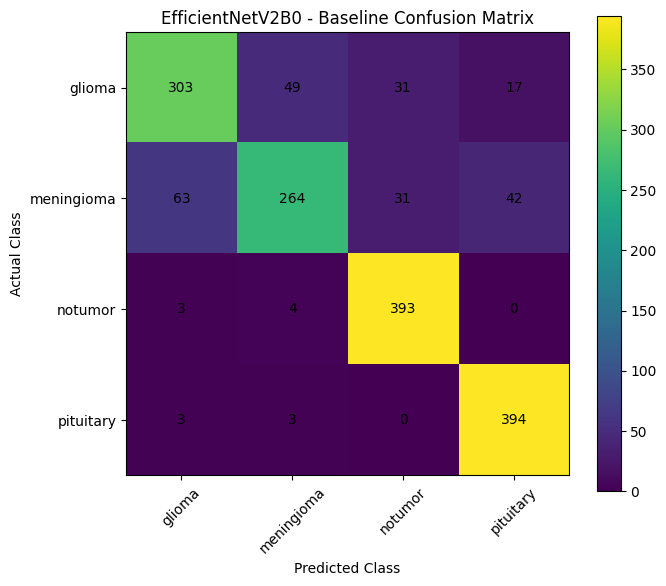

In [ ]:
cm_v2b0 = confusion_matrix(y_true_v2b0, y_pred_v2b0)

plt.figure(figsize=(7, 6))
plt.imshow(cm_v2b0)

plt.title("EfficientNetV2B0 - Baseline Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.xticks(range(len(class_names)), class_names, rotation=45)
plt.yticks(range(len(class_names)), class_names)

for i in range(len(class_names)):
    for j in range(len(class_names)):
        plt.text(
            j, i, cm_v2b0[i, j],
            ha="center",
            va="center"
        )

plt.colorbar()
plt.tight_layout()
plt.show()

In [ ]:
base_model_v2b0.trainable = True

# Freeze all layers except the last 30
for layer in base_model_v2b0.layers[:-30]:
    layer.trainable = False

# Keep BatchNormalization layers frozen
for layer in base_model_v2b0.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

model_v2b0.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("EfficientNetV2B0 fine-tuning model compiled.")
print("Trainable layers:", sum(layer.trainable for layer in base_model_v2b0.layers))

EfficientNetV2B0 fine-tuning model compiled.
Trainable layers: 24


In [ ]:
history_v2b0_ft = model_v2b0.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=5,
            restore_best_weights=True
        )
    ]
)

Epoch 1/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 29s 123ms/step - accuracy: 0.8884 - loss: 0.3101 - val_accuracy: 0.8857 - val_loss: 0.3240
Epoch 2/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 13s 93ms/step - accuracy: 0.8864 - loss: 0.2973 - val_accuracy: 0.8866 - val_loss: 0.3229
Epoch 3/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 13s 93ms/step - accuracy: 0.8900 - loss: 0.2891 - val_accuracy: 0.8857 - val_loss: 0.3184
Epoch 4/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 13s 92ms/step - accuracy: 0.8946 - loss: 0.2831 - val_accuracy: 0.8804 - val_loss: 0.3388
Epoch 5/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 13s 96ms/step - accuracy: 0.8931 - loss: 0.2854 - val_accuracy: 0.8893 - val_loss: 0.3152
Epoch 6/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 20s 93ms/step - accuracy: 0.8924 - loss: 0.2839 - val_accuracy: 0.8911 - val_loss: 0.3100
Epoch 7/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 20s 93ms/step - accuracy: 0.8955 - loss: 0.2737 - val_accuracy: 0.8920 - val_loss: 0.3149
Epoch 8/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 13s 96ms/step - accuracy: 0.8989 - loss: 0.2721 -

In [ ]:
test_loss_v2b0_ft, test_accuracy_v2b0_ft = model_v2b0.evaluate(test_ds)

print("Fine-tuned EfficientNetV2B0 Test Loss:", test_loss_v2b0_ft)
print("Fine-tuned EfficientNetV2B0 Test Accuracy:", test_accuracy_v2b0_ft)

50/50 ━━━━━━━━━━━━━━━━━━━━ 4s 74ms/step - accuracy: 0.8531 - loss: 0.4357
Fine-tuned EfficientNetV2B0 Test Loss: 0.4357188940048218
Fine-tuned EfficientNetV2B0 Test Accuracy: 0.8531249761581421


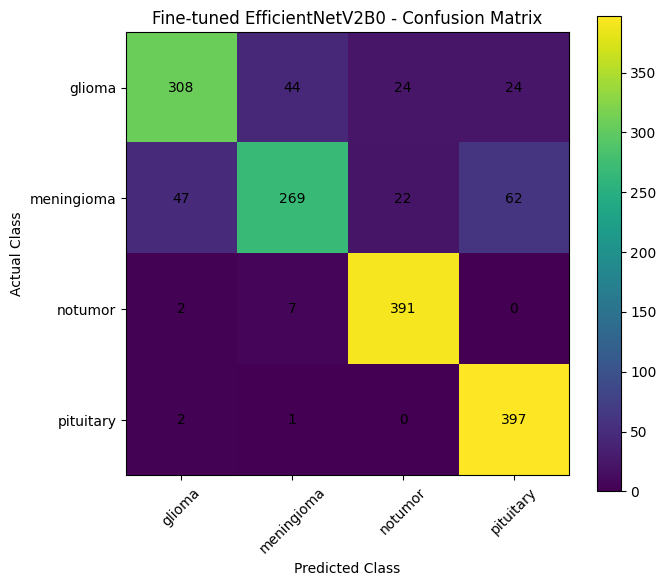

In [ ]:
from sklearn.metrics import confusion_matrix
import numpy as np
import matplotlib.pyplot as plt

y_true_v2b0_ft = []
y_pred_v2b0_ft = []

for images, labels in test_ds:
    predictions = model_v2b0.predict(images, verbose=0)

    y_true_v2b0_ft.extend(labels.numpy())
    y_pred_v2b0_ft.extend(np.argmax(predictions, axis=1))

y_true_v2b0_ft = np.array(y_true_v2b0_ft)
y_pred_v2b0_ft = np.array(y_pred_v2b0_ft)

cm_v2b0_ft = confusion_matrix(
    y_true_v2b0_ft,
    y_pred_v2b0_ft
)

plt.figure(figsize=(7, 6))
plt.imshow(cm_v2b0_ft)

plt.title("Fine-tuned EfficientNetV2B0 - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.xticks(range(len(class_names)), class_names, rotation=45)
plt.yticks(range(len(class_names)), class_names)

for i in range(len(class_names)):
    for j in range(len(class_names)):
        plt.text(
            j, i,
            cm_v2b0_ft[i, j],
            ha="center",
            va="center"
        )

plt.colorbar()
plt.tight_layout()
plt.show()

# **ResNet50**

In [ ]:
base_model_resnet50 = tf.keras.applications.ResNet50(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

base_model_resnet50.trainable = False

print("ResNet50 loaded.")
print("Total layers:", len(base_model_resnet50.layers))

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step
ResNet50 loaded.
Total layers: 175


In [ ]:
model_resnet50 = tf.keras.Sequential([
    data_augmentation,

    base_model_resnet50,

    tf.keras.layers.GlobalAveragePooling2D(),

    tf.keras.layers.Dropout(0.3),

    tf.keras.layers.Dense(
        num_classes,
        activation="softmax"
    )
])

model_resnet50.build((None, 224, 224, 3))

model_resnet50.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │         8,196 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,595,908 (90.01 MB)

 Trainable params: 8,196 (32.02 KB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [ ]:
model_resnet50.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history_resnet50 = model_resnet50.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=5,
            restore_best_weights=True
        )
    ]
)

Epoch 1/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 34s 185ms/step - accuracy: 0.8292 - loss: 0.4559 - val_accuracy: 0.8554 - val_loss: 0.3646
Epoch 2/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 24s 173ms/step - accuracy: 0.8299 - loss: 0.4439 - val_accuracy: 0.8670 - val_loss: 0.3504
Epoch 3/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 24s 170ms/step - accuracy: 0.8424 - loss: 0.4297 - val_accuracy: 0.8652 - val_loss: 0.3477
Epoch 4/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 24s 169ms/step - accuracy: 0.8440 - loss: 0.4096 - val_accuracy: 0.8714 - val_loss: 0.3385
Epoch 5/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 24s 170ms/step - accuracy: 0.8458 - loss: 0.4055 - val_accuracy: 0.8732 - val_loss: 0.3333
Epoch 6/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 24s 169ms/step - accuracy: 0.8498 - loss: 0.3969 - val_accuracy: 0.8714 - val_loss: 0.3385
Epoch 7/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 24s 168ms/step - accuracy: 0.8641 - loss: 0.3756 - val_accuracy: 0.8848 - val_loss: 0.3128
Epoch 8/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 41s 169ms/step - accuracy: 0.8585 - loss: 0

In [ ]:
test_loss_resnet50, test_accuracy_resnet50 = model_resnet50.evaluate(test_ds)

print("ResNet50 Baseline Test Loss:", test_loss_resnet50)
print("ResNet50 Baseline Test Accuracy:", test_accuracy_resnet50)

50/50 ━━━━━━━━━━━━━━━━━━━━ 7s 130ms/step - accuracy: 0.8519 - loss: 0.4801
ResNet50 Baseline Test Loss: 0.48007914423942566
ResNet50 Baseline Test Accuracy: 0.8518750071525574


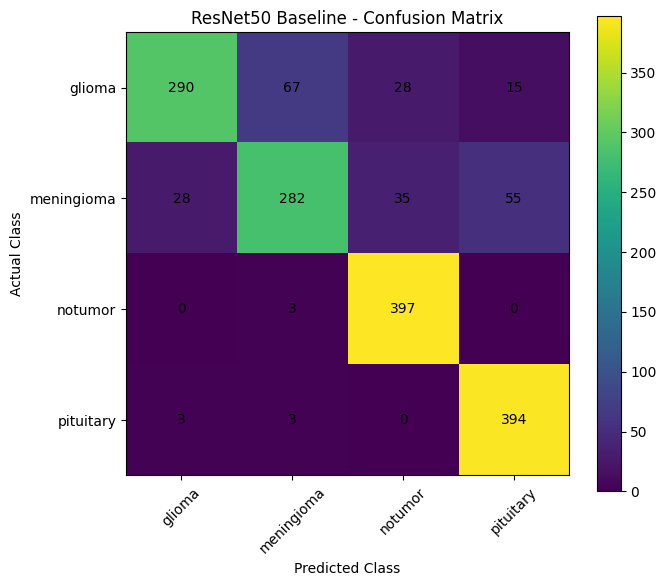

In [ ]:
from sklearn.metrics import confusion_matrix
import numpy as np
import matplotlib.pyplot as plt

y_true_resnet50 = []
y_pred_resnet50 = []

for images, labels in test_ds:
    predictions = model_resnet50.predict(images, verbose=0)

    y_true_resnet50.extend(labels.numpy())
    y_pred_resnet50.extend(np.argmax(predictions, axis=1))

y_true_resnet50 = np.array(y_true_resnet50)
y_pred_resnet50 = np.array(y_pred_resnet50)

cm_resnet50 = confusion_matrix(
    y_true_resnet50,
    y_pred_resnet50
)

plt.figure(figsize=(7, 6))
plt.imshow(cm_resnet50)

plt.title("ResNet50 Baseline - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.xticks(range(len(class_names)), class_names, rotation=45)
plt.yticks(range(len(class_names)), class_names)

for i in range(len(class_names)):
    for j in range(len(class_names)):
        plt.text(
            j, i,
            cm_resnet50[i, j],
            ha="center",
            va="center"
        )

plt.colorbar()
plt.tight_layout()
plt.show()

In [ ]:
# Fine-tuning ResNet50
base_model_resnet50.trainable = True

# Freeze all layers first
for layer in base_model_resnet50.layers:
    layer.trainable = False

# Unfreeze the last 30 layers
for layer in base_model_resnet50.layers[-30:]:
    layer.trainable = True

# Keep Batch Normalization layers frozen
for layer in base_model_resnet50.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

# Check trainable layers
trainable_count = sum(
    1 for layer in base_model_resnet50.layers
    if layer.trainable
)

print("ResNet50 fine-tuning model compiled.")
print("Trainable layers:", trainable_count)

ResNet50 fine-tuning model compiled.
Trainable layers: 21


In [ ]:
model_resnet50.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-5
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)


In [ ]:
history_resnet50_ft = model_resnet50.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=5,
            restore_best_weights=True
        )
    ]
)

Epoch 1/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 43s 238ms/step - accuracy: 0.9029 - loss: 0.2645 - val_accuracy: 0.9134 - val_loss: 0.2226
Epoch 2/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 36s 208ms/step - accuracy: 0.9225 - loss: 0.2025 - val_accuracy: 0.9161 - val_loss: 0.2322
Epoch 3/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 42s 215ms/step - accuracy: 0.9350 - loss: 0.1742 - val_accuracy: 0.9286 - val_loss: 0.1848
Epoch 4/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 30s 211ms/step - accuracy: 0.9478 - loss: 0.1447 - val_accuracy: 0.9402 - val_loss: 0.1556
Epoch 5/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 29s 208ms/step - accuracy: 0.9600 - loss: 0.1067 - val_accuracy: 0.9179 - val_loss: 0.2190
Epoch 6/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 30s 211ms/step - accuracy: 0.9623 - loss: 0.0958 - val_accuracy: 0.9286 - val_loss: 0.1958
Epoch 7/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 29s 209ms/step - accuracy: 0.9699 - loss: 0.0824 - val_accuracy: 0.9295 - val_loss: 0.2011
Epoch 8/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 29s 210ms/step - accuracy: 0.9739 - loss: 0

In [ ]:
test_loss_resnet50_ft, test_accuracy_resnet50_ft = model_resnet50.evaluate(test_ds)

print("Fine-tuned ResNet50 Test Loss:", test_loss_resnet50_ft)
print("Fine-tuned ResNet50 Test Accuracy:", test_accuracy_resnet50_ft)

50/50 ━━━━━━━━━━━━━━━━━━━━ 7s 141ms/step - accuracy: 0.9362 - loss: 0.4924
Fine-tuned ResNet50 Test Loss: 0.4923989474773407
Fine-tuned ResNet50 Test Accuracy: 0.9362499713897705


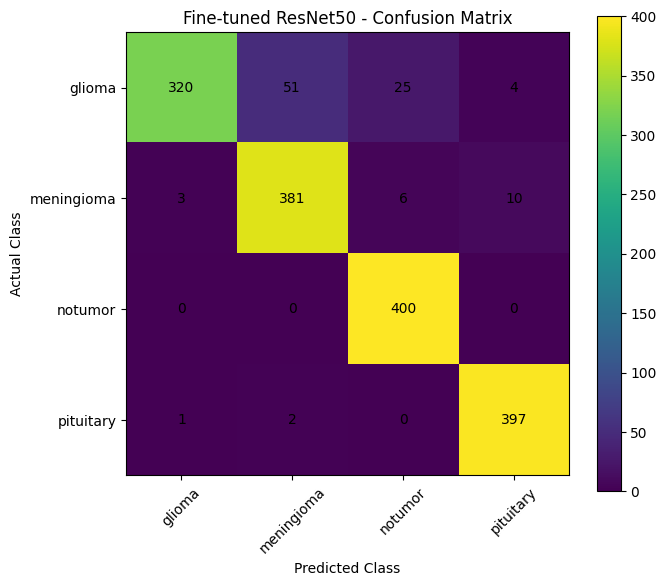

In [ ]:
from sklearn.metrics import confusion_matrix
import numpy as np
import matplotlib.pyplot as plt

y_true_resnet50_ft = []
y_pred_resnet50_ft = []

for images, labels in test_ds:
    predictions = model_resnet50.predict(images, verbose=0)

    y_true_resnet50_ft.extend(labels.numpy())
    y_pred_resnet50_ft.extend(np.argmax(predictions, axis=1))

y_true_resnet50_ft = np.array(y_true_resnet50_ft)
y_pred_resnet50_ft = np.array(y_pred_resnet50_ft)

cm_resnet50_ft = confusion_matrix(
    y_true_resnet50_ft,
    y_pred_resnet50_ft
)

plt.figure(figsize=(7, 6))
plt.imshow(cm_resnet50_ft)

plt.title("Fine-tuned ResNet50 - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.xticks(range(len(class_names)), class_names, rotation=45)
plt.yticks(range(len(class_names)), class_names)

for i in range(len(class_names)):
    for j in range(len(class_names)):
        plt.text(
            j, i,
            cm_resnet50_ft[i, j],
            ha="center",
            va="center"
        )

plt.colorbar()
plt.tight_layout()
plt.show()

# **ResNet101V2**

In [ ]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))

# Load ResNet101V2
resnet101v2 = tf.keras.applications.ResNet101V2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

print("ResNet101V2 loaded.")
print("Total layers:", len(resnet101v2.layers))

TensorFlow version: 2.20.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
171317808/171317808 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step
ResNet101V2 loaded.
Total layers: 377


In [ ]:
# Freeze the ResNet101V2 base model
resnet101v2.trainable = False

# Build the complete model
model_resnet101v2 = tf.keras.Sequential([
    data_augmentation,
    resnet101v2,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(4, activation="softmax")
])

# Compile
model_resnet101v2.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Display architecture
model_resnet101v2.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet101v2 (Functional)        │ (None, 7, 7, 2048)     │    42,626,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ ?                      │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 42,626,560 (162.61 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 42,626,560 (162.61 MB)

In [ ]:
history_resnet101v2 = model_resnet101v2.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30
)

Epoch 1/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 53s 267ms/step - accuracy: 0.3460 - loss: 56.5745 - val_accuracy: 0.6062 - val_loss: 8.8250
Epoch 2/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 36s 254ms/step - accuracy: 0.4542 - loss: 23.2615 - val_accuracy: 0.6089 - val_loss: 7.4831
Epoch 3/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 36s 259ms/step - accuracy: 0.4987 - loss: 14.0121 - val_accuracy: 0.6071 - val_loss: 9.2854
Epoch 4/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 35s 254ms/step - accuracy: 0.5232 - loss: 10.9022 - val_accuracy: 0.5839 - val_loss: 8.5097
Epoch 5/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 39s 279ms/step - accuracy: 0.5411 - loss: 7.5236 - val_accuracy: 0.5848 - val_loss: 6.1817
Epoch 6/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 36s 255ms/step - accuracy: 0.5540 - loss: 6.5876 - val_accuracy: 0.6679 - val_loss: 4.3896
Epoch 7/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 41s 257ms/step - accuracy: 0.5471 - loss: 7.1362 - val_accuracy: 0.6384 - val_loss: 5.2243
Epoch 8/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 36s 255ms/step - accuracy: 0.5676 - los

In [ ]:
test_loss, test_accuracy = model_resnet101v2.evaluate(test_ds)

print("ResNet101V2 Baseline Test Loss:", test_loss)
print("ResNet101V2 Baseline Test Accuracy:", test_accuracy)

50/50 ━━━━━━━━━━━━━━━━━━━━ 10s 204ms/step - accuracy: 0.4919 - loss: 7.9820
ResNet101V2 Baseline Test Loss: 7.982039928436279
ResNet101V2 Baseline Test Accuracy: 0.4918749928474426


Confusion Matrix:
[[331   4  65   0]
 [239  29 132   0]
 [ 15   3 382   0]
 [250   1 104  45]]


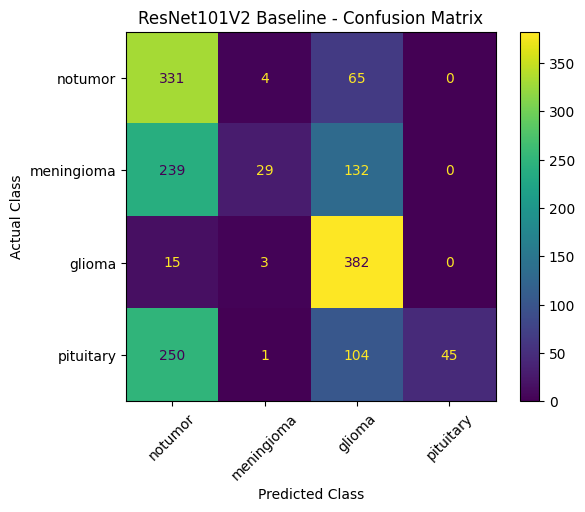

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

class_names = ['notumor', 'meningioma', 'glioma', 'pituitary']

y_true = []
y_pred = []

for images, labels in test_ds:
    predictions = model_resnet101v2.predict(images, verbose=0)
    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(predictions, axis=1))

cm = confusion_matrix(y_true, y_pred)

print("Confusion Matrix:")
print(cm)

# Same colour style as previous confusion matrices
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(
    cmap='viridis',
    xticks_rotation=45
)

plt.title("ResNet101V2 Baseline - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()

In [ ]:
# Fine-tuning ResNet101V2

# Freeze the entire backbone first
model_resnet101v2.layers[1].trainable = True

# Freeze all layers of ResNet101V2
for layer in model_resnet101v2.layers[1].layers:
    layer.trainable = False

# Unfreeze the last 30 layers
for layer in model_resnet101v2.layers[1].layers[-30:]:
    if not isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = True

# Compile with a small learning rate
model_resnet101v2.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Count trainable layers
trainable_count = sum(
    1 for layer in model_resnet101v2.layers[1].layers
    if layer.trainable
)

print("ResNet101V2 fine-tuning model compiled.")
print("Trainable layers:", trainable_count)

ResNet101V2 fine-tuning model compiled.
Trainable layers: 22


In [ ]:
history_resnet101v2_ft = model_resnet101v2.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30
)

Epoch 1/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 67s 328ms/step - accuracy: 0.6031 - loss: 2.6459 - val_accuracy: 0.6893 - val_loss: 1.3873
Epoch 2/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 45s 319ms/step - accuracy: 0.6167 - loss: 1.8818 - val_accuracy: 0.7080 - val_loss: 1.1049
Epoch 3/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 42s 298ms/step - accuracy: 0.6286 - loss: 1.5231 - val_accuracy: 0.7134 - val_loss: 0.9588
Epoch 4/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 42s 298ms/step - accuracy: 0.6551 - loss: 1.2504 - val_accuracy: 0.7688 - val_loss: 0.7490
Epoch 5/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 42s 299ms/step - accuracy: 0.6614 - loss: 1.0862 - val_accuracy: 0.7768 - val_loss: 0.6653
Epoch 6/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 42s 298ms/step - accuracy: 0.6875 - loss: 0.9878 - val_accuracy: 0.7848 - val_loss: 0.6492
Epoch 7/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 42s 298ms/step - accuracy: 0.7025 - loss: 0.8830 - val_accuracy: 0.7554 - val_loss: 0.6982
Epoch 8/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 42s 298ms/step - accuracy: 0.6993 - loss: 0

In [ ]:
test_loss, test_accuracy = model_resnet101v2.evaluate(test_ds)

print("Fine-tuned ResNet101V2 Test Loss:", test_loss)
print("Fine-tuned ResNet101V2 Test Accuracy:", test_accuracy)

50/50 ━━━━━━━━━━━━━━━━━━━━ 11s 223ms/step - accuracy: 0.7394 - loss: 0.8795
Fine-tuned ResNet101V2 Test Loss: 0.8795353770256042
Fine-tuned ResNet101V2 Test Accuracy: 0.7393749952316284


Confusion Matrix:
[[265  40  43  52]
 [118 139  36 107]
 [  2   3 393   2]
 [ 13   0   1 386]]


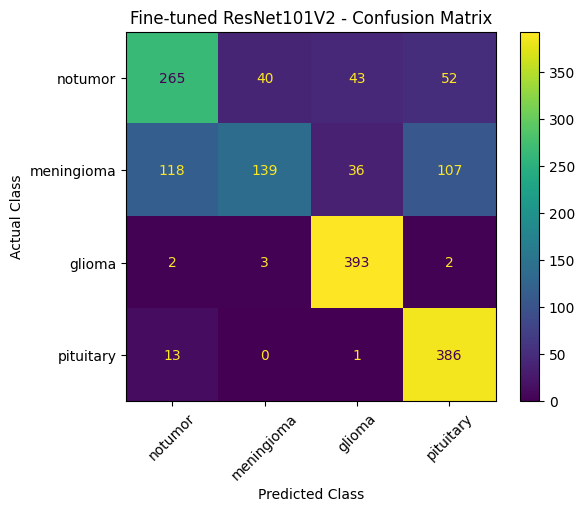

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import numpy as np
import matplotlib.pyplot as plt

class_names = ['notumor', 'meningioma', 'glioma', 'pituitary']

y_true = []
y_pred = []

for images, labels in test_ds:
    predictions = model_resnet101v2.predict(images, verbose=0)
    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(predictions, axis=1))

cm = confusion_matrix(y_true, y_pred)

print("Confusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(
    cmap='viridis',
    xticks_rotation=45
)

plt.title("Fine-tuned ResNet101V2 - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()